# 17 · Q5 signal or artifact: inventory check, chart and recommendation

If demand was real, stock should fall when sales rise. If the signal were a reporting lag, stock would move on a different day than sales.

In [1]:
import os
import pandas as pd
import numpy as np

DATA_DIR = next(d for d in ('data', '../data', '../../data') if os.path.isdir(d))
MISSING_TOKENS = {'', 'null', 'n/a', 'na', 'nan', 'none'}
DECISION_LOG = []

def log_decision(step, decision, rows_touched, rows_before=None, rows_after=None):
    DECISION_LOG.append({'step': step, 'decision': decision, 'rows_touched': int(rows_touched),
                         'rows_before': rows_before, 'rows_after': rows_after})


In [2]:
CATEGORY_MAP = {
    'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'electronics': 'Electronics',
    'emergency': 'Emergency', 'emergency supplies': 'Emergency',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'health': 'Health', 'health & wellness': 'Health',
    'household': 'Household', 'household essentials': 'Household',
    'snacks': 'Snacks',
}
TS_FORMATS = ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M',
              '%d-%b-%Y %H:%M', '%m-%d-%Y %H:%M:%S']

def load_transactions():
    return pd.read_csv(os.path.join(DATA_DIR, 'walmart_transactions.csv'), dtype=str)

def standardize_missing(df):
    """Strip whitespace; turn '', NULL, N/A, NaN... into real NaN."""
    out = df.copy()
    touched = 0
    for c in out.columns:
        s = out[c].str.strip()
        newly_na = s.str.lower().isin(MISSING_TOKENS) & out[c].notna()
        touched += int(newly_na.sum())
        out[c] = s.mask(newly_na)
    log_decision('missing', 'strip whitespace; blank/NULL/N-A tokens -> NaN (cells, not rows)', touched, len(df), len(out))
    return out

def remove_duplicates(df):
    n0 = len(df)
    out = df.drop_duplicates()
    log_decision('duplicates', 'drop exact duplicate rows (keep first)', n0 - len(out), n0, len(out))
    n1 = len(out)
    out = out.drop_duplicates('transaction_id')
    log_decision('duplicates', 'drop repeated transaction_id (keep first)', n1 - len(out), n1, len(out))
    return out

def clean_unit_price(df):
    out = df.copy()
    raw = out['unit_price']
    dollar = int(raw.str.contains('$', regex=False, na=False).sum())
    out['unit_price'] = pd.to_numeric(raw.str.replace('$', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
    bad = int(out['unit_price'].isna().sum() - raw.isna().sum())
    log_decision('unit_price', "remove '$', cast text -> float", dollar, len(df), len(out))
    log_decision('unit_price', 'values that still failed numeric cast -> NaN', bad, len(df), len(out))
    return out

def clean_quantity(df):
    out = df.copy()
    out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')
    n0 = len(out)
    out = out[out['quantity'] > 0]
    log_decision('quantity', 'drop rows with negative/zero/unparseable quantity (entry errors; sign-flip not assumed)', n0 - len(out), n0, len(out))
    return out

def parse_timestamps(df):
    out = df.copy()
    ts = pd.Series(pd.NaT, index=out.index, dtype='datetime64[ns]')
    for fmt in TS_FORMATS:
        todo = ts.isna() & out['timestamp'].notna()
        ts[todo] = pd.to_datetime(out.loc[todo, 'timestamp'], format=fmt, errors='coerce')
    unparsed = int((ts.isna() & out['timestamp'].notna()).sum())
    missing = int(out['timestamp'].isna().sum())
    out['timestamp'] = ts
    log_decision('timestamp', f'parse {len(TS_FORMATS)} mixed formats into one datetime (naive local time); {unparsed} unparseable', int(ts.notna().sum()), len(df), len(out))
    log_decision('timestamp', 'missing timestamps kept (NaT) but excluded from any date-based analysis; not imputed', missing, len(df), len(out))
    return out

def clean_store_id(df):
    out = df.copy()
    raw = out['store_id']
    out['store_id'] = (raw.str.upper().str.replace('_', '-', regex=False)
                          .str.replace(r'^FL-?(\d{3})$', r'FL-\1', regex=True))
    log_decision('store_id', "uppercase, strip, '_'/missing '-' -> canonical 'FL-###'", int((raw != out['store_id']).sum()), len(df), len(out))
    return out

def clean_category(df):
    out = df.copy()
    raw = out['category']
    out['category'] = raw.str.lower().map(CATEGORY_MAP)
    log_decision('category', f'collapse {raw.nunique()} spellings into {out["category"].nunique()} canonical categories', int((raw != out['category']).sum()), len(df), len(out))
    return out

def clean_transactions():
    DECISION_LOG.clear()
    df = load_transactions()
    for step in (standardize_missing, remove_duplicates, clean_unit_price, clean_quantity,
                 parse_timestamps, clean_store_id, clean_category):
        df = step(df)
    df['product_name_raw'] = df['product_name']
    return df.reset_index(drop=True)


In [3]:
def build_sku_map(df):
    """Group SKUs that share product names (union-find over sku <-> normalized name)."""
    names = df[['sku', 'product_name']].dropna().assign(name=lambda d: d['product_name'].str.lower().str.strip())
    parent = {}
    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for sku, name in names[['sku', 'name']].drop_duplicates().itertuples(index=False):
        parent[find(('sku', sku))] = find(('name', name))
    names['group'] = names['sku'].map(lambda s: find(('sku', s)))
    sku_group = names.drop_duplicates('sku').set_index('sku')['group']
    ids = {g: i + 1 for i, g in enumerate(sorted(sku_group.unique(), key=str))}
    # canonical name = most common mixed-case product_name in the group (skips ALL-CAPS / lowercase variants)
    mixed = names[~names['product_name'].str.isupper() & ~names['product_name'].str.islower()]
    top_name = (mixed.assign(pid=mixed['group'].map(ids)).groupby('pid')['product_name']
                .agg(lambda s: s.str.strip().value_counts().idxmax()))
    out = pd.DataFrame({'sku': sku_group.index, 'canonical_id': sku_group.map(ids).values})
    out['canonical_name'] = out['canonical_id'].map(top_name)
    return out.sort_values(['canonical_id', 'sku']).reset_index(drop=True)


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

tx_clean = clean_transactions()
dated = tx_clean.dropna(subset=['timestamp']).assign(day=lambda x: x['timestamp'].dt.normalize())
print('rows used (have a timestamp):', len(dated), 'of', len(tx_clean))


rows used (have a timestamp): 24521 of 25402


In [5]:
# Windows. Landfall (Hurricane Helene, Big Bend, FL) was the night of Sept 26, 2024 (external fact, not in the data).
# Baseline = Sept 1-15: daily orders sit flat at ~580 before the first step-up on Sept 16.
# Surge   = the 7 days before landfall day: Sept 19-25.
BASELINE = (pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15'))
SURGE = (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))

daily_cat = dated.groupby(['day', 'category'])['quantity'].sum().unstack(fill_value=0)
base = daily_cat.loc[BASELINE[0]:BASELINE[1]].mean()
surge = daily_cat.loc[SURGE[0]:SURGE[1]].mean()
q1 = pd.DataFrame({'baseline_avg_units': base, 'surge_avg_units': surge})
q1['multiple'] = q1['surge_avg_units'] / q1['baseline_avg_units']
q1['pct_increase'] = (q1['multiple'] - 1) * 100
q1 = q1.sort_values('pct_increase', ascending=False).round(2)

tot_base, tot_surge = daily_cat.loc[BASELINE[0]:BASELINE[1]].sum(axis=1).mean(), daily_cat.loc[SURGE[0]:SURGE[1]].sum(axis=1).mean()
q1_multiple = tot_surge / tot_base
print(f'baseline window: {BASELINE[0].date()} to {BASELINE[1].date()} ({(BASELINE[1]-BASELINE[0]).days+1} days)')
print(f'surge window:    {SURGE[0].date()} to {SURGE[1].date()} ({(SURGE[1]-SURGE[0]).days+1} days)')
print(f'all categories: {tot_base:.0f} units/day -> {tot_surge:.0f} units/day = {q1_multiple:.2f}x')
q1


baseline window: 2024-09-01 to 2024-09-15 (15 days)
surge window:    2024-09-19 to 2024-09-25 (7 days)
all categories: 1103 units/day -> 2712 units/day = 2.46x


,baseline_avg_units,surge_avg_units,multiple,pct_increase
category,,,,
Breakfast,73.27,376.86,5.14,414.36
Emergency,354.07,1006.43,2.84,184.25
Electronics,70.27,175.86,2.50,150.27
Alcohol,61.53,138.86,2.26,125.66
Entertainment,101.60,228.57,2.25,124.97
Health,42.33,95.00,2.24,124.41
Household,85.13,176.29,2.07,107.07
Grocery,171.07,306.57,1.79,79.21
Baby,85.20,133.71,1.57,56.94


In [6]:
import sqlite3
con = sqlite3.connect(os.path.join(DATA_DIR, 'inventory_and_sales.db'))
print(pd.read_sql("SELECT name, sql FROM sqlite_master WHERE type='table'", con).to_string())

# Problem 1: mixed date formats in daily_sales_summary
print('\ndate string lengths:'); print(pd.read_sql('SELECT length(date) AS len, COUNT(*) AS n FROM daily_sales_summary GROUP BY len', con))
q_week = "SELECT COUNT(*) AS n FROM daily_sales_summary WHERE category = 'Entertainment' AND {col} BETWEEN {a} AND {b}"
naive = pd.read_sql(q_week.format(col='date', a="'2024-09-19'", b="'2024-09-25'"), con)['n'][0]
fixed = pd.read_sql(q_week.format(col="REPLACE(date, '-', '')", a="'20240919'", b="'20240925'"), con)['n'][0]
print(f'Entertainment rows in Sept 19-25 (expect 12 stores x 7 days = 84): naive date filter = {naive}, after normalising = {fixed}')
assert fixed == 84

# Entertainment daily units straight from SQL, dates normalised
ds = pd.read_sql("SELECT REPLACE(date, '-', '') AS d, SUM(total_units) AS units FROM daily_sales_summary "
                 "WHERE category = 'Entertainment' GROUP BY d ORDER BY d", con)
ent_db = ds.assign(day=pd.to_datetime(ds['d'], format='%Y%m%d')).set_index('day')['units']
assert len(ent_db) == 30

def surge_stats(s):
    base = s.loc['2024-09-01':'2024-09-15'].mean()
    return {'baseline_avg': round(base, 1),
            'week_avg_pct': round((s.loc['2024-09-19':'2024-09-25'].mean() / base - 1) * 100, 1),
            'peak_day_pct': round((s.max() / base - 1) * 100, 1), 'peak_day': str(s.idxmax().date())}

good = pd.read_sql("SELECT date, SUM(total_units) AS units FROM daily_sales_summary WHERE category = 'Entertainment' AND length(date) = 10 GROUP BY date", con)
ent_naive = good.assign(day=pd.to_datetime(good['date'])).set_index('day')['units']
print('\nEntertainment surge, SQL totals with dates normalised:', surge_stats(ent_db))
print('Entertainment surge if the 218 YYYYMMDD rows are silently dropped:', surge_stats(ent_naive))


                  name                                                                                                                                                                        sql
0  daily_sales_summary                               CREATE TABLE daily_sales_summary (\n    date TEXT,\n    store_id TEXT,\n    category TEXT,\n    total_units REAL,\n    total_revenue REAL\n)
1     inventory_levels  CREATE TABLE inventory_levels (\n    date TEXT,\n    store_id TEXT,\n    sku TEXT,\n    units_on_hand INTEGER,\n    units_on_order INTEGER,\n    reorder_point INTEGER\n)

date string lengths:
   len     n
0    8   218
1   10  3382
Entertainment rows in Sept 19-25 (expect 12 stores x 7 days = 84): naive date filter = 78, after normalising = 84

Entertainment surge, SQL totals with dates normalised: {'baseline_avg': np.float64(568.5), 'week_avg_pct': np.float64(145.3), 'peak_day_pct': np.float64(271.7), 'peak_day': '2024-09-24'}
Entertainment surge if the 218 YYYYMMDD rows are silent

In [7]:
# --- same Entertainment surge, DB vs transactions CSV, plus rank among all categories
allcat = pd.read_sql("SELECT REPLACE(date, '-', '') AS d, category, SUM(total_units) AS units FROM daily_sales_summary GROUP BY d, category", con)
allcat['day'] = pd.to_datetime(allcat['d'], format='%Y%m%d')
db_cat = allcat.pivot(index='day', columns='category', values='units')
db_pct = (db_cat.loc[SURGE[0]:SURGE[1]].mean() / db_cat.loc[BASELINE[0]:BASELINE[1]].mean() - 1) * 100
cmp = pd.DataFrame({'db_pct': db_pct, 'csv_pct': q1['pct_increase']}).round(1)
cmp['db_rank'] = cmp['db_pct'].rank(ascending=False).astype(int)
cmp['csv_rank'] = cmp['csv_pct'].rank(ascending=False).astype(int)
print(cmp.sort_values('db_pct', ascending=False))
r_daily = db_cat['Entertainment'].corr(daily_cat['Entertainment'])
print(f"\nEntertainment daily units, DB vs CSV: r={r_daily:.2f}; DB total {db_cat['Entertainment'].sum():.0f} vs CSV total {daily_cat['Entertainment'].sum():.0f} units (different scale, so compare % not levels)")

# --- SKU / category audit on the transactions
sku_map = build_sku_map(tx_clean)
tx_sku = tx_clean.merge(sku_map, on='sku', how='left')
ent = tx_sku[tx_sku['category'] == 'Entertainment']
print('\nSKUs under Entertainment:'); print(ent.groupby(['canonical_name', 'sku']).size())
raw = load_transactions()
print('\nraw category spellings on those SKUs:', raw.loc[raw['sku'].isin(ent['sku'].unique()), 'category'].str.strip().value_counts().to_dict())
# no miscoding: these products appear only under Entertainment, and nothing else sits in Entertainment
assert set(ent['canonical_name']) == {'Board Game - Monopoly', 'Playing Cards'}
assert tx_sku[tx_sku['canonical_name'].isin(ent['canonical_name'].unique())]['category'].eq('Entertainment').all()
print('audit passed: no SKU is miscoded across categories')

prod_daily = (ent.dropna(subset=['timestamp']).assign(day=lambda x: x['timestamp'].dt.normalize())
              .groupby(['day', 'canonical_name'])['quantity'].sum().unstack(fill_value=0))
prod = pd.DataFrame({'baseline_avg': prod_daily.loc[BASELINE[0]:BASELINE[1]].mean(), 'surge_avg': prod_daily.loc[SURGE[0]:SURGE[1]].mean()})
prod['pct_increase'] = (prod['surge_avg'] / prod['baseline_avg'] - 1) * 100
prod['peak_day_pct'] = (prod_daily.max() / prod['baseline_avg'] - 1) * 100   # single best day vs baseline
prod.round(1)


               db_pct  csv_pct  db_rank  csv_rank
category                                         
Breakfast       235.8    414.4        1         1
Emergency       182.6    184.2        2         2
Entertainment   145.3    125.0        3         5
Health          118.6    124.4        4         6
Alcohol         112.0    125.7        5         4
Household       103.9    107.1        6         7
Electronics      97.5    150.3        7         3
Grocery          62.4     79.2        8         8
Baby             54.2     56.9        9         9
Snacks           18.0     25.9       10        10

Entertainment daily units, DB vs CSV: r=0.96; DB total 24070 vs CSV total 4250 units (different scale, so compare % not levels)

SKUs under Entertainment:
canonical_name         sku         
Board Game - Monopoly  BG-MONO         430
                       GAME-MONO       464
                       MONOPOLY-01     439
Playing Cards          CARDS-01        584
                       PLAYCARD-STD 

,baseline_avg,surge_avg,pct_increase,peak_day_pct
canonical_name,,,,
Board Game - Monopoly,42.9,111.4,159.9,315.2
Playing Cards,58.7,117.1,99.4,189.4


board-game/card stock on hand (window averages): 133 units/store over Sept 12-20 vs 33 over Sept 21-25
share of store-SKUs below reorder point: 0% -> 59%
biggest one-day stock drop: 2024-09-21 | first day DB sales reached 2x baseline: 2024-09-21

inventory SKUs not in the transaction/catalog data: ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99'] = 355 of 4320 rows; inventory has no product names, so their contents cannot be checked; the five board-game/card SKUs themselves are all present


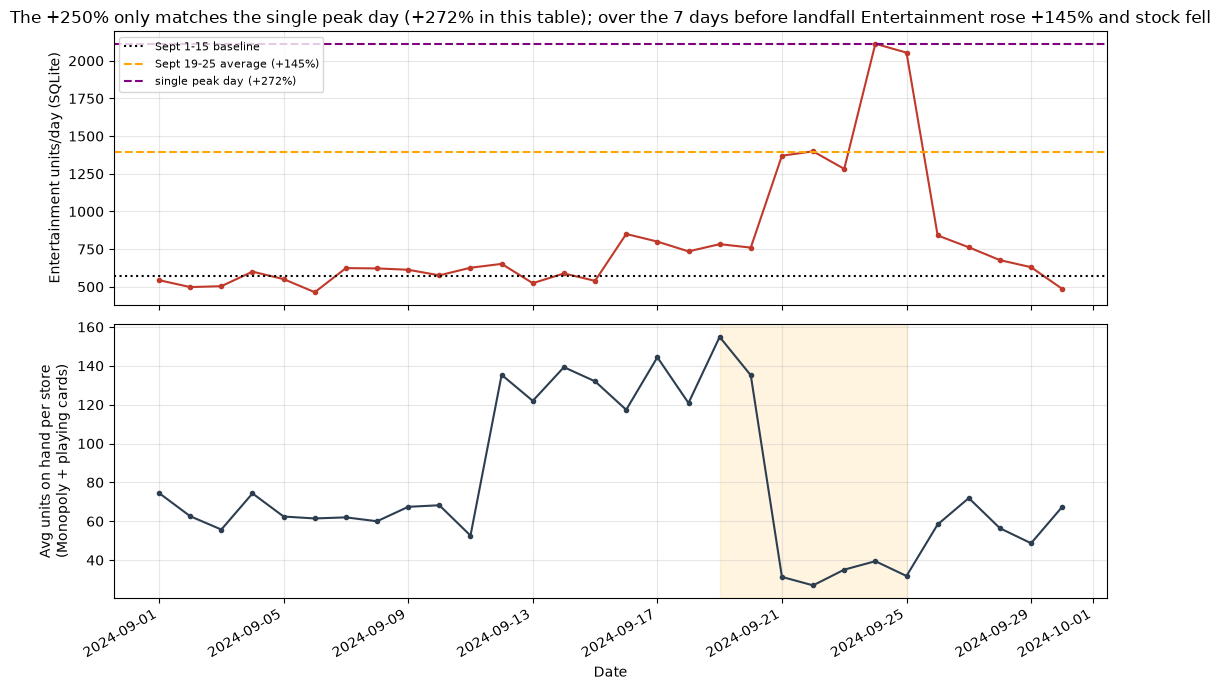

In [8]:
# --- inventory: did stock fall when demand rose, and is any of it a reporting lag?
skus = sku_map.loc[sku_map['canonical_name'].isin(['Board Game - Monopoly', 'Playing Cards']), 'sku'].tolist()
marks = ','.join('?' * len(skus))
inv = pd.read_sql(f'SELECT date, AVG(units_on_hand) AS on_hand, AVG(units_on_hand < reorder_point) AS pct_below_reorder '
                  f'FROM inventory_levels WHERE sku IN ({marks}) GROUP BY date', con, params=skus)
assert inv['date'].str.len().eq(10).all() and len(inv) == 30
assert set(skus) <= set(pd.read_sql('SELECT DISTINCT sku FROM inventory_levels', con)['sku']), 'a board-game/card SKU is missing from inventory'
inv['day'] = pd.to_datetime(inv['date'])
inv = inv.set_index('day')
pre, during = inv.loc['2024-09-12':'2024-09-20'], inv.loc['2024-09-21':'2024-09-25']
print(f"board-game/card stock on hand (window averages): {pre['on_hand'].mean():.0f} units/store over Sept 12-20 vs {during['on_hand'].mean():.0f} over Sept 21-25")
print(f"share of store-SKUs below reorder point: {pre['pct_below_reorder'].mean():.0%} -> {during['pct_below_reorder'].mean():.0%}")
first_big_drop = inv['on_hand'].diff().idxmin().date()
sales_2x = (ent_db.loc['2024-09-16':] >= 2 * ent_db.loc[BASELINE[0]:BASELINE[1]].mean()).idxmax().date()
print('biggest one-day stock drop:', first_big_drop, '| first day DB sales reached 2x baseline:', sales_2x)
assert first_big_drop == sales_2x, 'stock and sales moved on different days (possible reporting lag)'

known = set(sku_map['sku'])
inv_sku = pd.read_sql('SELECT sku, COUNT(*) AS n FROM inventory_levels GROUP BY sku', con)
unmapped = inv_sku[~inv_sku['sku'].isin(known)]
print(f"\ninventory SKUs not in the transaction/catalog data: {unmapped['sku'].tolist()} = {unmapped['n'].sum()} of {inv_sku['n'].sum()} rows; inventory has no product names, so their contents cannot be checked; the five board-game/card SKUs themselves are all present")

wk, pk = surge_stats(ent_db)['week_avg_pct'], surge_stats(ent_db)['peak_day_pct']
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
a1.plot(ent_db.index, ent_db, marker='o', ms=3, color='#c0392b')
b = ent_db.loc[BASELINE[0]:BASELINE[1]].mean()
a1.axhline(b, color='k', ls=':', label='Sept 1-15 baseline')
a1.axhline(b * (1 + wk / 100), color='orange', ls='--', label=f'Sept 19-25 average (+{wk:.0f}%)')
a1.axhline(ent_db.max(), color='purple', ls='--', label=f'single peak day (+{pk:.0f}%)')
a1.set_ylabel('Entertainment units/day (SQLite)')
a1.set_title(f'The +250% only matches the single peak day (+{pk:.0f}% in this table); over the 7 days before landfall Entertainment rose +{wk:.0f}% and stock fell')
a1.legend(fontsize=8); a1.grid(alpha=.3)
a2.plot(inv.index, inv['on_hand'], marker='o', ms=3, color='#2c3e50')
a2.set_ylabel('Avg units on hand per store\n(Monopoly + playing cards)'); a2.set_xlabel('Date'); a2.grid(alpha=.3)
a2.axvspan(SURGE[0], SURGE[1], color='orange', alpha=.12)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()


**Q5 answer and recommendation.** The rise is real demand, not a data artifact, but smaller than +250% on a weekly basis. The evidence: (1) a "+250%" is only reachable as a single-best-day figure for the whole Entertainment category, while the 7-day increase is +145% (database) or +125% (transactions), and Monopoly alone is +160%; (2) the two sources are consistent in direction and shape (r=0.96, mostly the shared step-up); (3) no SKU is miscoded, and both products rose; (4) board-game and card stock on hand averaged 133 units per store over Sept 12-20 and 33 over Sept 21-25, the largest one-day stock drop fell on Sept 21, the same day sales first reached 2x baseline, and 59% of store-SKUs were below their reorder point in the second window vs 0% in the first, so there is no reporting lag longer than one day (inventory is a once-a-day snapshot, so nothing finer can be ruled out); (5) the mixed date formats move the weekly figure only from +145% to +148%, and four inventory SKUs (355 of 4,320 rows) have no names so their contents cannot be checked, but all five board-game/card SKUs are present.

**Recommendation:** yes, stock extra board games for the next storm, sized for roughly 2.3-2.6x normal demand over the pre-landfall week (Entertainment +125% to +145%, Monopoly alone +160%), not 3.5x, and after Breakfast and Emergency supplies in priority. Demand started rising on Sept 16 and stepped up sharply on Sept 21, so stock should be on shelves by about Sept 16, roughly ten days before landfall, and certainly by Sept 21. Confidence limits: this is one storm, one month of synthetic data, and inventory has only daily snapshots.